![uwm_logo1_pl.svg](https://uwm.edu.pl/sites/default/files/2023-01/uwm_logo_poziome_PL.png)

# Symulacje komputerowe
## Laboratorium 01 - Wprowadzenie do wykresów 2D i 3D
**mgr inż. Adam Zalewski**<br>
na podstawie materiałów **dra hab. inż. Mariusza Bodziocha, prof. UWM**

**Zadanie 0.** Zaimportuj niezbędne biblioteki.

In [9]:
import numpy as np

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

from matplotlib import cm
from IPython.display import HTML

import warnings
warnings.filterwarnings("ignore")

**Zadanie 1.** Narysować trójkąt o wierzchołkach w punktach: $(0,0)$, $(10, 1)$, $(5,7)$.

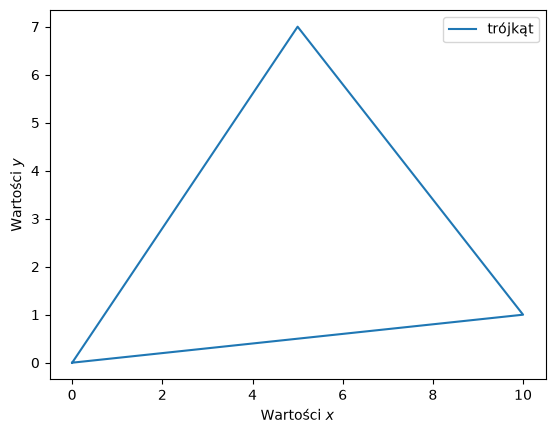

In [12]:
x = [0, 10, 5, 0]
y = [0, 1, 7, 0]

plt.plot(x, y, label='trójkąt')

plt.xlabel("Oś $x$")
plt.ylabel("Oś $y$")

plt.legend()

plt.show()

**Zadanie 2.** Na jednym wykresie narysuj trzy funkcje zgodnie z opisem:
- $f(x) = \sin x$ - kolor pomarańczowy, linia kropkowana
- $g(x) = \sin(2x)$ - kolor zielony, linia ciągła
- $h(x) = \sin(3x)$ - kolor czerwony, linia kreskowana

w przedziale $[0, 2\pi]$. Opisać osie wykresu, dodać legendę i tytuł "Wykresy trzech
funkcji" oraz włączyć wyświetlanie siatki pomocniczej.


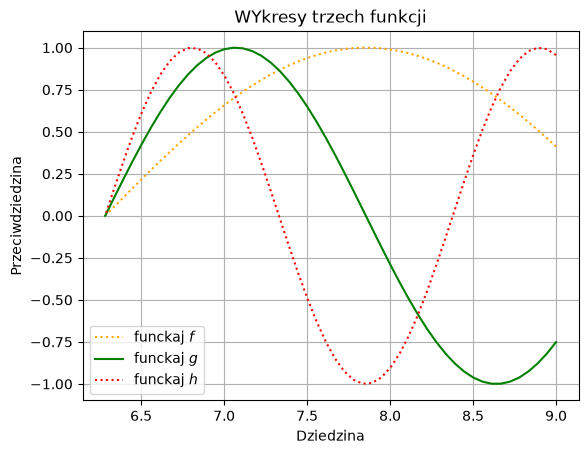

In [14]:
x = np.linspace(9, 2*np.pi)
f = np.sin(x)
g = np.sin(2 * x)
h = np.sin(3 * x)

plt.plot(x, f, "orange", label="funckaj $f$", linestyle=":")
plt.plot(x, g, "green", label="funckaj $g$")
plt.plot(x, h, "red", label="funckaj $h$", linestyle=":")

plt.title("WYkresy trzech funkcji")

plt.xlabel("Dziedzina")
plt.ylabel("Przeciwdziedzina")

plt.grid()

plt.legend()

plt.show()

**Zadanie 3.** Na dwóch wykresach umieszczonych jeden obok drugiego narysować funkcję $$y=sin(10^x)$$ w przedziale $[0, 4]$. Jeden wykres narysować stosując 1000 równomiernie rozłożonych punktów, a drugi stosując 100 równomiernie rozłożonych punktów. Opisać obie osie dodać legendy i tytuły.

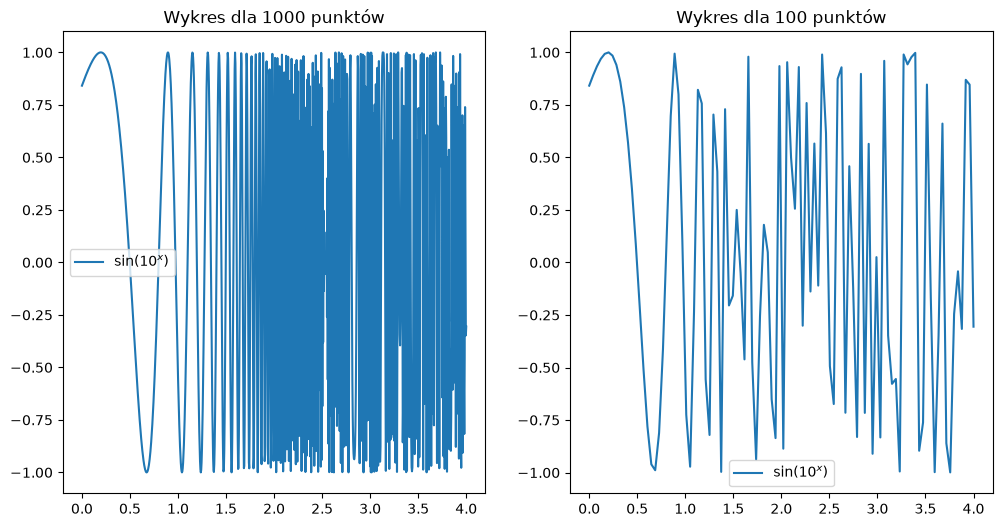

In [17]:
plt.figure(figsize=(12, 6))

plt.subplot(121)
x = np.linspace(0, 4, 1000)
y = np.sin(10**x)
plt.plot(x, y, label="$\sin(10^x)$")
plt.title("Wykres dla 1000 punktów")
plt.legend()

plt.subplot(122)
x = np.linspace(0, 4, 100)
y = np.sin(10**x)
plt.plot(x, y, label="$\sin(10^x)$")
plt.title("Wykres dla 100 punktów")
plt.legend()

plt.show()

Z czego wynikają różnice pomiędzy wykresami?

**Odpowiedź:**

**Zadanie 4.** W jednym oknie wygeneruj cztery wykresy 2D/3D funkcji $$f(x,y) = \cos(x)|\sin(y)|$$ dla $(x, y) \in [-2\pi, 2\pi]^2$ według podanych wymagań:
- wykres siatki 3D
- wykres powierzchni 3D
- wykres rzutu funkcji na płaszczyznę z konturami (sprawdź parametr *levels*)
- wykres powierzchni 3D z izoliniami

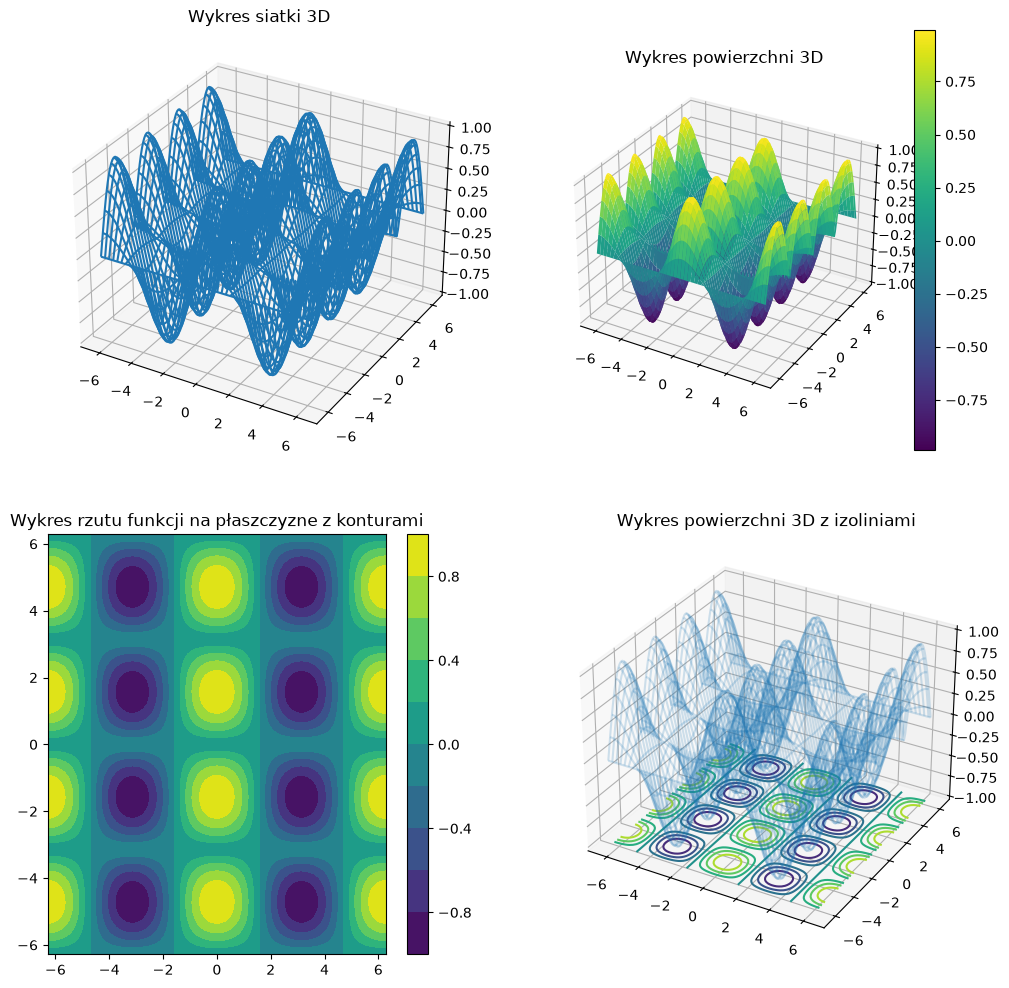

In [35]:
x = np.linspace(-2 * np.pi, 2 * np.pi, 100)
y = np.linspace(-2 * np.pi, 2 * np.pi, 100)

X, Y = np.meshgrid(x, y)

Z = np.cos(X) * abs(np.sin(Y))

fig = plt.figure(figsize=(12, 12))
ax1 = fig.add_subplot(221, projection='3d')
ax1.plot_wireframe(X, Y, Z)
ax1.set_title("Wykres siatki 3D")

ax2 = fig.add_subplot(222, projection='3d')
surf = ax2.plot_surface(X, Y, Z, cmap=cm.viridis)
fig.colorbar(surf, ax=ax2)
ax2.set_title("Wykres powierzchni 3D")

ax3 = fig.add_subplot(223)
contour = ax3.contourf(X, Y, Z, cmap=cm.viridis, levels = 10)
fig.colorbar(contour, ax=ax3)
ax3.set_title("Wykres rzutu funkcji na płaszczyzne z konturami")

ax4 = fig.add_subplot(224, projection='3d')
ax4.plot_wireframe(X, Y, Z, alpha=0.2)
ax4.contour(X, Y, Z, cmap=cm.viridis, offset=np.min(Z))
ax4.set_title("Wykres powierzchni 3D z izoliniami")

plt.show()

**Zadanie 5.** Narysuj krzywą daną parametrycznie:
$$x = \tan \frac{t}{2}$$
$$y = \cos \frac{t}{2}$$
$$z = \frac{t}{5}$$

dla $t\in [0,10\pi]$

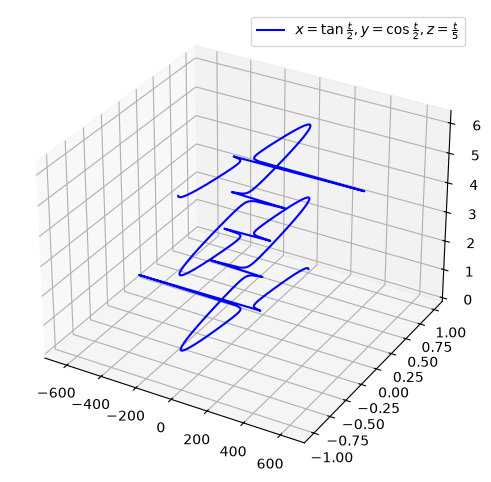

In [37]:
t = np.linspace(0, 10*np.pi, 1000)

x = np.tan(t/2)
y = np.cos(t/2)
z = t/5

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, label=r"$x=\tan\frac{t}{2}, y=\cos\frac{t}{2}, z=\frac{t}{5}$", color="blue")

ax.legend()

plt.show()

**Zadanie 6.** Utworzyć wykres powierzchni $$z=\cos{\left(x^\frac{1}{y}\right)}+\sin{\left(y^\frac{1}{x}\right)}$$ dla dodatnich $x$ i $y$, takich, że $x,y\leq 5$. Wykreślić izolinie na tym wykresie i ustawić kamerę na najwyższy punkt wykresu.

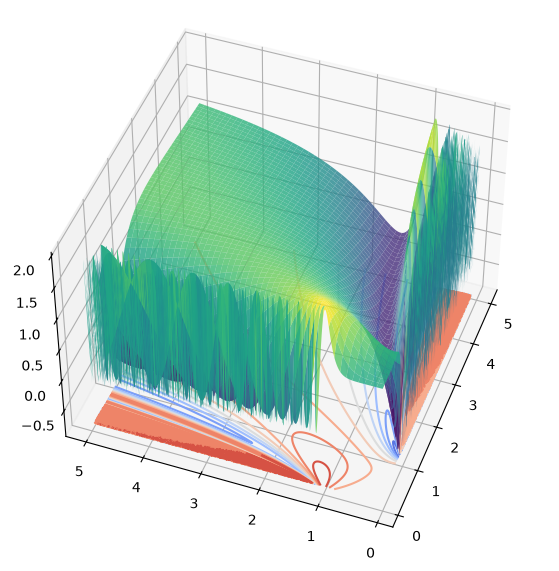

In [44]:
x = np.linspace(0.1, 5, 1000)
y = np.linspace(0.1, 5, 1000)
X, Y = np.meshgrid(x, y)

Z = np.cos(X**(1/Y)) + np.sin(Y**(1/X))

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, Z, cmap=cm.viridis, alpha=0.8)

ax.contour(X, Y, Z, levels=10, cmap=cm.coolwarm, offset=np.min(Z))

ax.view_init(elev=45, azim=200)

plt.show()

**Zadanie 7.** Utwórz wykres z zadania poprzedniego, tak aby był w odcieniach szarości. Izolinie podostaw w kolorze.

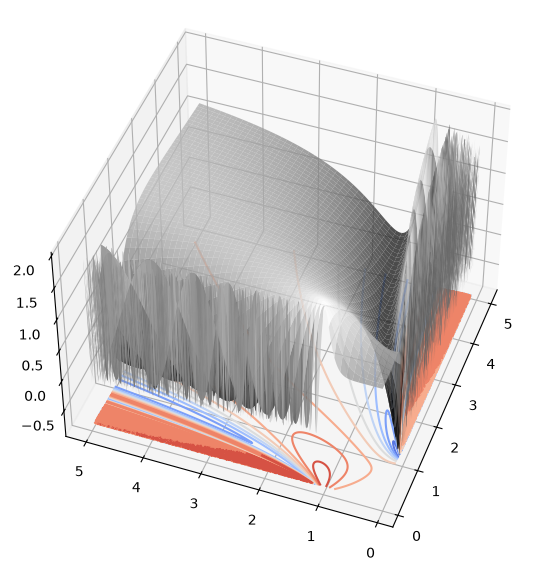

In [46]:
x = np.linspace(0.1, 5, 1000)
y = np.linspace(0.1, 5, 1000)
X, Y = np.meshgrid(x, y)

Z = np.cos(X**(1/Y)) + np.sin(Y**(1/X))

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, Z, cmap=cm.gray, alpha=0.8)

ax.contour(X, Y, Z, levels=10, cmap=cm.coolwarm, offset=np.min(Z))

ax.view_init(elev=45, azim=200)

plt.show()

**Zadanie 8.** Utworzyć tablicę A rozmiaru 1000×2 o elementach losowych z rozkładu normalnego.
Utworzyć tablicę B rozmiaru 1000 × 1 o elementach losowych z rozkładu jednostajnego na przedziale [0, 2]. Utworzyć histogramy reprezentujące rozkłady wartości
elementów z dwóch kolumn tabeli A. Jakie są wartości średnie i odchylenia standardowe? Utworzyć wykres punktowy dla danych z tablicy A. Zdefiniować kolor
reprezentujący wartości z tablicy B.

**Zadanie 9.** Na podstawie zadania 2 utwórz animację rysowania wykresów trzech funkcji i zapisz jako .gif.

**Zadanie 10.** Na podstawie zadania 2 utwórz animację rysowania wykresów trzech funkcji tak, żeby można było ją odtwarzać w przeglądarce.